In [2]:
import os
import re
import glob
import subprocess
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)

In [3]:
PHENO_PATH = "/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/phenotype_files/Training_Cov_file.txt"
PLINK_DIR = "/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files"

assert os.path.exists(PHENO_PATH), f"Phenotype file not found: {PHENO_PATH}"
assert os.path.exists(PLINK_DIR), f"PLINK directory not found: {PLINK_DIR}"

print("Phenotype path:", PHENO_PATH)
print("PLINK dir:", PLINK_DIR)

Phenotype path: /gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/phenotype_files/Training_Cov_file.txt
PLINK dir: /gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files


In [4]:
def human_readable_size(num_bytes):
    """Convert bytes to a human-readable string."""
    if pd.isna(num_bytes):
        return np.nan
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if num_bytes < 1024:
            return f"{num_bytes:.2f} {unit}"
        num_bytes /= 1024
    return f"{num_bytes:.2f} PB"


def safe_getsize(path):
    """Get file size safely."""
    if path is None or not os.path.exists(path):
        return np.nan
    return os.path.getsize(path)


def run_cmd(cmd, check=False):
    """
    Run shell command and capture stdout/stderr.
    cmd: list[str]
    """
    result = subprocess.run(cmd, capture_output=True, text=True)
    if check and result.returncode != 0:
        raise RuntimeError(
            f"Command failed:\n{' '.join(cmd)}\n\nstdout:\n{result.stdout}\n\nstderr:\n{result.stderr}"
        )
    return result

In [5]:
def load_pheno_file(pheno_path, sep="\t"):
    df = pd.read_csv(pheno_path, sep=sep)
    print("Phenotype shape:", df.shape)
    display(df.head())
    return df

pheno_df = load_pheno_file(PHENO_PATH)


Phenotype shape: (5811, 16)


,sampleid,sex,age_sd,PC1_sd,PC2_sd,PC3_sd,PC4_sd,PC5_sd,PC6_sd,PC7_sd,PC8_sd,PC9_sd,PC10_sd,cad,bc,T2D
0,S-781185,Male,1.288303,-0.555962,0.480146,0.224748,0.241001,0.320088,1.938814,0.348092,0.387093,0.610129,-0.450001,1,0,0
1,S-312853,Female,1.591000,-0.482392,0.222560,-0.349030,-0.697747,-0.539562,0.463947,-0.214933,0.386187,-0.588972,-0.390756,0,0,0
2,S-879678,Male,0.077515,0.154176,-3.259585,1.898367,-0.280359,-0.868405,0.188799,2.969257,-4.082796,1.091930,1.139250,1,0,1
3,S-964332,Female,-0.770037,1.364458,0.080234,0.323463,-0.224608,1.842692,-0.409662,-1.222077,0.806165,-0.700859,0.216519,0,0,0
4,S-734060,Male,0.440751,-0.562651,0.332478,-0.273394,-1.414405,-0.311043,-0.842868,-0.864892,-0.473900,-1.954522,1.386096,1,0,0


In [6]:
def identify_pheno_columns(df):
    cols = df.columns.tolist()
    lower_to_original = {c.lower(): c for c in cols}
    
    sample_col = None
    for cand in ["sampleid", "sample_id", "iid", "id"]:
        if cand in lower_to_original:
            sample_col = lower_to_original[cand]
            break
    
    sex_col = None
    for cand in ["sex", "gender"]:
        if cand in lower_to_original:
            sex_col = lower_to_original[cand]
            break
    
    age_col = None
    for cand in ["age_sd", "age"]:
        if cand in lower_to_original:
            age_col = lower_to_original[cand]
            break
    
    pc_cols = [c for c in cols if c.lower().startswith("pc")]
    
    phenotype_cols = []
    seen = set()
    for cand in ["cad", "bc", "bca", "t2d"]:
        if cand in lower_to_original:
            col = lower_to_original[cand]
            if col not in seen:
                phenotype_cols.append(col)
                seen.add(col)
    
    out = {
        "sample_col": sample_col,
        "sex_col": sex_col,
        "age_col": age_col,
        "pc_cols": pc_cols,
        "phenotype_cols": phenotype_cols,
    }
    
    print(out)
    return out

pheno_info = identify_pheno_columns(pheno_df)

{'sample_col': 'sampleid', 'sex_col': 'sex', 'age_col': 'age_sd', 'pc_cols': ['PC1_sd', 'PC2_sd', 'PC3_sd', 'PC4_sd', 'PC5_sd', 'PC6_sd', 'PC7_sd', 'PC8_sd', 'PC9_sd', 'PC10_sd'], 'phenotype_cols': ['cad', 'bc', 'T2D']}


In [7]:
def scan_plink_directory(plink_dir):
    """
    Scan PLINK directory and group files by prefix.
    Returns a dataframe with:
    - prefix
    - chromosome (best effort)
    - pgen_path / pvar_path / psam_path
    - sizes
    - file completeness
    """
    all_files = glob.glob(os.path.join(plink_dir, "*"))
    
    records = {}
    for path in all_files:
        p = Path(path)
        suffix = p.suffix.lower()
        if suffix not in [".pgen", ".pvar", ".psam", ".zst"]:
            continue
        
        # handle cases like .pvar.zst
        name = p.name
        if name.endswith(".pvar.zst"):
            prefix = name[:-len(".pvar.zst")]
            key = "pvar_zst_path"
        elif name.endswith(".pgen"):
            prefix = name[:-len(".pgen")]
            key = "pgen_path"
        elif name.endswith(".pvar"):
            prefix = name[:-len(".pvar")]
            key = "pvar_path"
        elif name.endswith(".psam"):
            prefix = name[:-len(".psam")]
            key = "psam_path"
        else:
            continue
        
        if prefix not in records:
            records[prefix] = {"prefix": prefix}
        records[prefix][key] = str(path)
    
    rows = []
    for prefix, rec in records.items():
        pgen_path = rec.get("pgen_path")
        pvar_path = rec.get("pvar_path")
        pvar_zst_path = rec.get("pvar_zst_path")
        psam_path = rec.get("psam_path")
        
        # chromosome parsing: best effort
        prefix_lower = prefix.lower()
        chr_match = None
        
        patterns = [
            r"(?:^|[_\.-])chr?(\d+|x|y|xy|mt|m)(?:$|[_\.-])",
            r"^chr?(\d+|x|y|xy|mt|m)$"
        ]
        for pat in patterns:
            m = re.search(pat, prefix_lower)
            if m:
                chr_match = m.group(1).upper()
                break
        
        rows.append({
            "prefix": prefix,
            "chromosome": chr_match,
            "pgen_path": pgen_path,
            "pvar_path": pvar_path,
            "pvar_zst_path": pvar_zst_path,
            "psam_path": psam_path,
            "has_pgen": pgen_path is not None,
            "has_pvar": (pvar_path is not None) or (pvar_zst_path is not None),
            "has_psam": psam_path is not None,
            "pgen_size_bytes": safe_getsize(pgen_path),
            "pvar_size_bytes": safe_getsize(pvar_path) if pvar_path is not None else safe_getsize(pvar_zst_path),
            "psam_size_bytes": safe_getsize(psam_path),
        })
    
    df = pd.DataFrame(rows)
    if len(df) == 0:
        print("No PLINK files detected.")
        return df
    
    df["complete_triplet"] = df["has_pgen"] & df["has_pvar"] & df["has_psam"]
    df["pgen_size"] = df["pgen_size_bytes"].apply(human_readable_size)
    df["pvar_size"] = df["pvar_size_bytes"].apply(human_readable_size)
    df["psam_size"] = df["psam_size_bytes"].apply(human_readable_size)
    
    # sort best-effort by chromosome then prefix
    def chr_sort_key(x):
        if pd.isna(x):
            return 999
        if str(x).isdigit():
            return int(x)
        mapping = {"X": 23, "Y": 24, "XY": 25, "M": 26, "MT": 26}
        return mapping.get(str(x).upper(), 998)
    
    df = df.sort_values(
        by=["chromosome", "prefix"],
        key=lambda col: col.map(chr_sort_key) if col.name == "chromosome" else col
    ).reset_index(drop=True)
    
    return df

plink_scan_df = scan_plink_directory(PLINK_DIR)
display(plink_scan_df)

,prefix,chromosome,pgen_path,pvar_path,pvar_zst_path,psam_path,has_pgen,has_pvar,has_psam,pgen_size_bytes,pvar_size_bytes,psam_size_bytes,complete_triplet,pgen_size,pvar_size,psam_size
0,Testing_Chr1,1,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr1.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr1.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr1.psam,True,True,True,9162193152,170322081,103989,True,8.53 GB,162.43 MB,101.55 KB
1,Testing_Chr2,2,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr2.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr2.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr2.psam,True,True,True,9587970007,185080760,103989,True,8.93 GB,176.51 MB,101.55 KB
2,Testing_Chr3,3,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr3.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr3.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr3.psam,True,True,True,8186314726,151464456,103989,True,7.62 GB,144.45 MB,101.55 KB
3,Testing_Chr4,4,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr4.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr4.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr4.psam,True,True,True,8197086041,148565869,103989,True,7.63 GB,141.68 MB,101.55 KB
4,Testing_Chr5,5,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr5.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr5.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr5.psam,True,True,True,7285441046,138282778,103989,True,6.79 GB,131.88 MB,101.55 KB
5,Testing_Chr6,6,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr6.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr6.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr6.psam,True,True,True,6968079697,132064820,103989,True,6.49 GB,125.95 MB,101.55 KB
6,Testing_Chr7,7,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr7.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr7.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr7.psam,True,True,True,6747193931,123748344,103989,True,6.28 GB,118.02 MB,101.55 KB
7,Testing_Chr8,8,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr8.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr8.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr8.psam,True,True,True,6214766107,117873969,103989,True,5.79 GB,112.41 MB,101.55 KB
8,Testing_Chr9,9,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr9.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr9.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr9.psam,True,True,True,5676019998,92453535,103989,True,5.29 GB,88.17 MB,101.55 KB
9,Testing_Chr10,10,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr10.pgen,/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr10.pvar,None,/gpfs/data/deciphEHRlab/deciphEHRdream

In [8]:
def summarize_plink_scan(plink_scan_df):
    if plink_scan_df.empty:
        print("Empty scan result.")
        return
    
    print("Number of detected prefixes:", len(plink_scan_df))
    print("Complete triplets:", plink_scan_df["complete_triplet"].sum())
    print("Incomplete entries:", (~plink_scan_df["complete_triplet"]).sum())
    
    print("\nChromosome distribution:")
    display(plink_scan_df["chromosome"].value_counts(dropna=False).sort_index())
    
    display(
        plink_scan_df[
            ["prefix", "chromosome", "complete_triplet", "pgen_size", "pvar_size", "psam_size"]
        ]
    )

summarize_plink_scan(plink_scan_df)

Number of detected prefixes: 22
Complete triplets: 22
Incomplete entries: 0

Chromosome distribution:


chromosome
1     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
2     1
20    1
21    1
22    1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
Name: count, dtype: int64

,prefix,chromosome,complete_triplet,pgen_size,pvar_size,psam_size
0,Testing_Chr1,1,True,8.53 GB,162.43 MB,101.55 KB
1,Testing_Chr2,2,True,8.93 GB,176.51 MB,101.55 KB
2,Testing_Chr3,3,True,7.62 GB,144.45 MB,101.55 KB
3,Testing_Chr4,4,True,7.63 GB,141.68 MB,101.55 KB
4,Testing_Chr5,5,True,6.79 GB,131.88 MB,101.55 KB
5,Testing_Chr6,6,True,6.49 GB,125.95 MB,101.55 KB
6,Testing_Chr7,7,True,6.28 GB,118.02 MB,101.55 KB
7,Testing_Chr8,8,True,5.79 GB,112.41 MB,101.55 KB
8,Testing_Chr9,9,True,5.29 GB,88.17 MB,101.55 KB
9,Testing_Chr10,10,True,5.34 GB,105.10 MB,101.55 KB


/tmp/ipykernel_3480950/1387582846.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plot_df["prefix"], rotation=90)


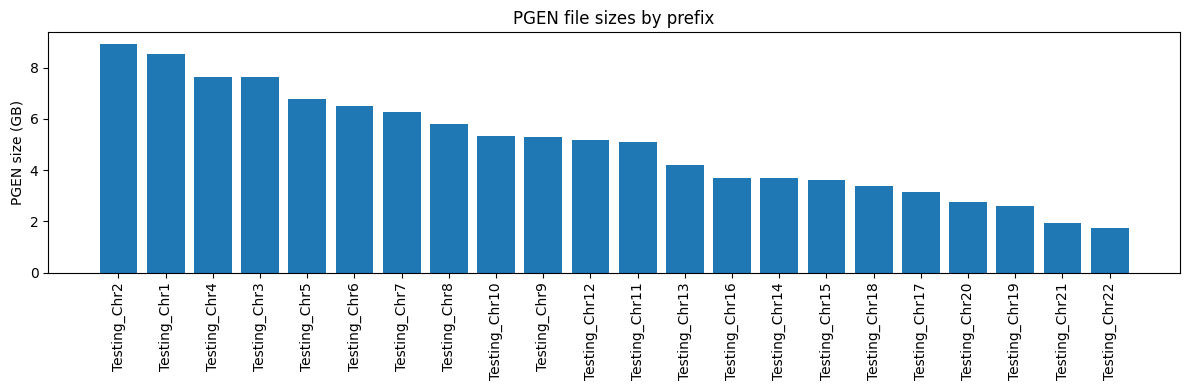

In [9]:
def plot_pgen_file_sizes(plink_scan_df):
    if plink_scan_df.empty:
        print("Empty scan result.")
        return
    
    plot_df = plink_scan_df.copy()
    plot_df = plot_df.sort_values("pgen_size_bytes", ascending=False)
    
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(plot_df["prefix"], plot_df["pgen_size_bytes"] / (1024**3))
    ax.set_xticklabels(plot_df["prefix"], rotation=90)
    ax.set_ylabel("PGEN size (GB)")
    ax.set_title("PGEN file sizes by prefix")
    plt.tight_layout()
    plt.show()

plot_pgen_file_sizes(plink_scan_df)

In [10]:
def choose_chr1_prefix(plink_scan_df):
    if plink_scan_df.empty:
        raise ValueError("PLINK scan dataframe is empty.")
    
    chr1_df = plink_scan_df[
        plink_scan_df["chromosome"].astype(str).str.upper() == "1"
    ]
    chr1_df = chr1_df[chr1_df["complete_triplet"]]
    
    if len(chr1_df) > 0:
        chosen = chr1_df.iloc[0]
        print("Automatically selected chr1 prefix:", chosen["prefix"])
        return chosen["prefix"]
    
    # fallback: first complete prefix
    complete_df = plink_scan_df[plink_scan_df["complete_triplet"]]
    if len(complete_df) == 0:
        raise ValueError("No complete PLINK triplet found.")
    
    chosen = complete_df.iloc[0]
    print("chr1 not found automatically. Fallback prefix:", chosen["prefix"])
    return chosen["prefix"]

CHR1_PREFIX = choose_chr1_prefix(plink_scan_df)
CHR1_PREFIX

Automatically selected chr1 prefix: Testing_Chr1


'Testing_Chr1'

In [11]:
def get_prefix_row(plink_scan_df, prefix):
    row = plink_scan_df.loc[plink_scan_df["prefix"] == prefix]
    if len(row) == 0:
        raise ValueError(f"Prefix not found: {prefix}")
    return row.iloc[0]


def read_psam(psam_path):
    """
    Read PLINK2 .psam.
    PLINK2 .psam is whitespace-delimited, often with header line starting with '#IID' or '#FID'.
    """
    df = pd.read_csv(psam_path, sep=r"\s+", engine="python")
    print("PSAM shape:", df.shape)
    display(df.head())
    return df


def read_pvar(pvar_path=None, pvar_zst_path=None, nrows=None):
    """
    Read .pvar or .pvar.zst.
    """
    if pvar_path is not None and os.path.exists(pvar_path):
        df = pd.read_csv(pvar_path, sep=r"\s+", comment="#", header=None, nrows=nrows, engine="python")
        print("PVAR raw shape:", df.shape)
        display(df.head())
        return df
    
    if pvar_zst_path is not None and os.path.exists(pvar_zst_path):
        df = pd.read_csv(pvar_zst_path, sep=r"\s+", comment="#", header=None, nrows=nrows, compression="zstd", engine="python")
        print("PVAR raw shape:", df.shape)
        display(df.head())
        return df
    
    raise ValueError("Neither pvar_path nor pvar_zst_path is available.")


chr1_row = get_prefix_row(plink_scan_df, CHR1_PREFIX)
psam_df = read_psam(chr1_row["psam_path"])
pvar_raw_df = read_pvar(chr1_row["pvar_path"], chr1_row["pvar_zst_path"], nrows=10)

PSAM shape: (8665, 2)


,#IID,SEX
0,S-861679,NaN
1,S-730677,NaN
2,S-404107,NaN
3,S-395845,NaN
4,S-226054,NaN


PVAR raw shape: (10, 5)


,0,1,2,3,4
0,1,10454,c1_10454_snv_C_T,C,T
1,1,14521,c1_14521_snv_C_T,C,T
2,1,14610,c1_14610_snv_T_C,T,C
3,1,14653,c1_14653_snv_C_T,C,T
4,1,14671,c1_14671_snv_G_C,G,C


In [12]:
def read_pvar_with_header(pvar_path=None, pvar_zst_path=None, nrows=None):
    open_kwargs = dict(sep=r"\s+", engine="python", nrows=nrows)
    
    if pvar_path is not None and os.path.exists(pvar_path):
        # keep header
        df = pd.read_csv(pvar_path, **open_kwargs)
    elif pvar_zst_path is not None and os.path.exists(pvar_zst_path):
        df = pd.read_csv(pvar_zst_path, compression="zstd", **open_kwargs)
    else:
        raise ValueError("Neither pvar_path nor pvar_zst_path is available.")
    
    print("PVAR shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
    return df

pvar_df = read_pvar_with_header(chr1_row["pvar_path"], chr1_row["pvar_zst_path"], nrows=20)

PVAR shape: (20, 5)
Columns: ['#CHROM', 'POS', 'ID', 'REF', 'ALT']


,#CHROM,POS,ID,REF,ALT
0,1,10454,c1_10454_snv_C_T,C,T
1,1,14521,c1_14521_snv_C_T,C,T
2,1,14610,c1_14610_snv_T_C,T,C
3,1,14653,c1_14653_snv_C_T,C,T
4,1,14671,c1_14671_snv_G_C,G,C


In [13]:
def detect_psam_sample_col(psam_df):
    candidates = ["IID", "#IID", "SAMPLE", "sampleid", "sample_id"]
    for c in candidates:
        if c in psam_df.columns:
            return c
    # fallback
    for c in psam_df.columns:
        if "iid" in c.lower():
            return c
    return None


def compare_samples(pheno_df, pheno_sample_col, psam_df, psam_sample_col):
    pheno_ids = pheno_df[pheno_sample_col].astype(str)
    psam_ids = psam_df[psam_sample_col].astype(str)
    
    pheno_set = set(pheno_ids)
    psam_set = set(psam_ids)
    
    in_pheno_not_psam = sorted(list(pheno_set - psam_set))
    in_psam_not_pheno = sorted(list(psam_set - pheno_set))
    
    ordered_match = False
    same_length = len(pheno_ids) == len(psam_ids)
    if same_length:
        ordered_match = (pheno_ids.reset_index(drop=True) == psam_ids.reset_index(drop=True)).all()
    
    result = {
        "n_pheno_samples": len(pheno_ids),
        "n_psam_samples": len(psam_ids),
        "n_common_samples": len(pheno_set & psam_set),
        "n_in_pheno_not_psam": len(in_pheno_not_psam),
        "n_in_psam_not_pheno": len(in_psam_not_pheno),
        "ordered_match": ordered_match,
        "same_length": same_length,
        "example_in_pheno_not_psam": in_pheno_not_psam[:10],
        "example_in_psam_not_pheno": in_psam_not_pheno[:10],
    }
    
    return result


psam_sample_col = detect_psam_sample_col(psam_df)
print("Detected PSAM sample column:", psam_sample_col)

sample_cmp = compare_samples(
    pheno_df=pheno_df,
    pheno_sample_col=pheno_info["sample_col"],
    psam_df=psam_df,
    psam_sample_col=psam_sample_col
)

sample_cmp

Detected PSAM sample column: #IID


{'n_pheno_samples': 5811,
 'n_psam_samples': 8665,
 'n_common_samples': 5811,
 'n_in_pheno_not_psam': 0,
 'n_in_psam_not_pheno': 2854,
 'ordered_match': False,
 'same_length': False,
 'example_in_pheno_not_psam': [],
 'example_in_psam_not_pheno': ['S-100253',
  'S-100566',
  'S-101104',
  'S-101572',
  'S-102129',
  'S-102596',
  'S-102697',
  'S-103235',
  'S-103570',
  'S-103812']}

In [14]:
def display_sample_comparison(sample_cmp):
    summary_df = pd.DataFrame({
        "metric": list(sample_cmp.keys()),
        "value": list(sample_cmp.values())
    })
    display(summary_df)

display_sample_comparison(sample_cmp)

,metric,value
0,n_pheno_samples,5811
1,n_psam_samples,8665
2,n_common_samples,5811
3,n_in_pheno_not_psam,0
4,n_in_psam_not_pheno,2854
5,ordered_match,False
6,same_length,False
7,example_in_pheno_not_psam,[]
8,example_in_psam_not_pheno,"[S-100253, S-100566, S-101104, S-101572, S-102129, S-102596, S-102697, S-103235, S-103570, S-103812]"


In [15]:
def merge_pheno_psam(pheno_df, pheno_sample_col, psam_df, psam_sample_col):
    merged = pheno_df.merge(
        psam_df,
        left_on=pheno_sample_col,
        right_on=psam_sample_col,
        how="inner",
        suffixes=("_pheno", "_psam")
    )
    print("Merged shape:", merged.shape)
    display(merged.head())
    return merged

merged_df = merge_pheno_psam(
    pheno_df, pheno_info["sample_col"],
    psam_df, psam_sample_col
)

Merged shape: (5811, 18)


,sampleid,sex,age_sd,PC1_sd,PC2_sd,PC3_sd,PC4_sd,PC5_sd,PC6_sd,PC7_sd,PC8_sd,PC9_sd,PC10_sd,cad,bc,T2D,#IID,SEX
0,S-781185,Male,1.288303,-0.555962,0.480146,0.224748,0.241001,0.320088,1.938814,0.348092,0.387093,0.610129,-0.450001,1,0,0,S-781185,NaN
1,S-312853,Female,1.591000,-0.482392,0.222560,-0.349030,-0.697747,-0.539562,0.463947,-0.214933,0.386187,-0.588972,-0.390756,0,0,0,S-312853,NaN
2,S-879678,Male,0.077515,0.154176,-3.259585,1.898367,-0.280359,-0.868405,0.188799,2.969257,-4.082796,1.091930,1.139250,1,0,1,S-879678,NaN
3,S-964332,Female,-0.770037,1.364458,0.080234,0.323463,-0.224608,1.842692,-0.409662,-1.222077,0.806165,-0.700859,0.216519,0,0,0,S-964332,NaN
4,S-734060,Male,0.440751,-0.562651,0.332478,-0.273394,-1.414405,-0.311043,-0.842868,-0.864892,-0.473900,-1.954522,1.386096,1,0,0,S-734060,NaN


In [16]:
def inspect_pvar_basic(pvar_df):
    print("Shape:", pvar_df.shape)
    print("Columns:", pvar_df.columns.tolist())
    
    summary = {}
    
    # chromosome column
    chrom_col = None
    for c in pvar_df.columns:
        if c.lower().replace("#", "") in ["chrom", "chr"]:
            chrom_col = c
            break
    summary["chrom_col"] = chrom_col
    
    # position column
    pos_col = None
    for c in pvar_df.columns:
        if c.lower() == "pos":
            pos_col = c
            break
    summary["pos_col"] = pos_col
    
    # id column
    id_col = None
    for c in pvar_df.columns:
        if c.lower() == "id":
            id_col = c
            break
    summary["id_col"] = id_col
    
    # ref / alt
    ref_col, alt_col = None, None
    for c in pvar_df.columns:
        if c.lower() == "ref":
            ref_col = c
        if c.lower() == "alt":
            alt_col = c
    summary["ref_col"] = ref_col
    summary["alt_col"] = alt_col
    
    print("\nDetected columns:")
    print(summary)
    
    if chrom_col is not None:
        print("\nChromosome value counts:")
        display(pvar_df[chrom_col].value_counts(dropna=False).head(20))
    
    if id_col is not None:
        n_dup = pvar_df[id_col].duplicated().sum()
        print(f"\nDuplicated variant IDs: {n_dup}")
    
    if ref_col is not None and alt_col is not None:
        allele_df = pvar_df[[ref_col, alt_col]].copy()
        print("\nTop REF/ALT combinations:")
        display(
            allele_df.value_counts().head(20).rename("count").reset_index()
        )

inspect_pvar_basic(pvar_df)

Shape: (20, 5)
Columns: ['#CHROM', 'POS', 'ID', 'REF', 'ALT']

Detected columns:
{'chrom_col': '#CHROM', 'pos_col': 'POS', 'id_col': 'ID', 'ref_col': 'REF', 'alt_col': 'ALT'}

Chromosome value counts:


#CHROM
1    20
Name: count, dtype: int64


Duplicated variant IDs: 0

Top REF/ALT combinations:


,REF,ALT,count
0,C,T,7
1,G,A,6
2,A,G,3
3,T,C,1
4,G,C,1
5,C,G,1
6,A,C,1


In [17]:
def count_pvar_variants(pvar_path=None, pvar_zst_path=None):
    """
    Count number of variant rows in .pvar / .pvar.zst excluding header.
    """
    if pvar_path is not None and os.path.exists(pvar_path):
        with open(pvar_path, "r") as f:
            n = sum(1 for _ in f) - 1
        return n
    
    if pvar_zst_path is not None and os.path.exists(pvar_zst_path):
        # use python zstandard if available; otherwise fallback to shell
        try:
            import zstandard as zstd
            with open(pvar_zst_path, "rb") as fh:
                dctx = zstd.ZstdDecompressor()
                with dctx.stream_reader(fh) as reader:
                    text_stream = pd.io.common.get_handle(reader, "r", encoding="utf-8")
                    # fallback line counting from decompressed stream
            # simpler: shell fallback below
        except Exception:
            pass
        
        # shell fallback
        result = run_cmd(["bash", "-lc", f"zstdcat {pvar_zst_path} | wc -l"])
        if result.returncode != 0:
            raise RuntimeError(result.stderr)
        n_lines = int(result.stdout.strip())
        return n_lines - 1
    
    raise ValueError("Neither pvar_path nor pvar_zst_path available.")

n_chr1_variants = count_pvar_variants(chr1_row["pvar_path"], chr1_row["pvar_zst_path"])
print("Estimated number of chr1 variants:", n_chr1_variants)

Estimated number of chr1 variants: 4692475


In [18]:
print("Phenotype samples:", pheno_df.shape[0])
print("PSAM samples:", psam_df.shape[0])
print("Merged samples:", merged_df.shape[0])

Phenotype samples: 5811
PSAM samples: 8665
Merged samples: 5811


In [19]:
def check_plink2_available():
    result = run_cmd(["bash", "-lc", "which plink2"])
    if result.returncode == 0:
        return result.stdout.strip()
    return None

plink2_path = check_plink2_available()
print("plink2 path:", plink2_path)

plink2 path: /gpfs/share/apps/plink/2.0-20260228/plink2


In [20]:
def run_plink2_freq(prefix_row, out_prefix):
    """
    Run plink2 --freq on one prefix.
    """
    if plink2_path is None:
        print("plink2 not available. Skip.")
        return None
    
    # pfile prefix should not include extension
    pfile_prefix = os.path.join(PLINK_DIR, prefix_row["prefix"])
    
    cmd = [
        "plink2",
        "--pfile", pfile_prefix,
        "--freq",
        "--out", out_prefix
    ]
    
    print("Running:", " ".join(cmd))
    result = run_cmd(cmd)
    print("Return code:", result.returncode)
    print("stdout:", result.stdout[:1000])
    print("stderr:", result.stderr[:2000])
    
    return result

OUT_DIR = "./plink_qc_tmp"
os.makedirs(OUT_DIR, exist_ok=True)

freq_out_prefix = os.path.join(OUT_DIR, f"{CHR1_PREFIX}_freq")
freq_result = run_plink2_freq(chr1_row, freq_out_prefix)

Running: plink2 --pfile /gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr1 --freq --out ./plink_qc_tmp/Testing_Chr1_freq
Return code: 0
stdout: PLINK v2.0.0-a.6.33LM 64-bit Intel (28 Feb 2026)    cog-genomics.org/plink/2.0/
(C) 2005-2026 Shaun Purcell, Christopher Chang    GNU General Public License v3
Logging to ./plink_qc_tmp/Testing_Chr1_freq.log.
Options in effect:
  --freq
  --out ./plink_qc_tmp/Testing_Chr1_freq
  --pfile /gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr1

Start time: Thu Apr  9 15:28:18 2026
385609 MiB RAM detected, ~356946 available; reserving 192804 MiB for main
workspace.
Using up to 4 compute threads.
8665 samples (0 females, 0 males, 8665 ambiguous; 8665 founders) loaded from
/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/plink_files/Testing_Chr1.psam.
4692475 variants loaded from
/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/genotype_files/pl

In [21]:
def read_plink2_freq(freq_out_prefix):
    afreq_path = freq_out_prefix + ".afreq"
    if not os.path.exists(afreq_path):
        print("AFREQ file not found:", afreq_path)
        return None
    
    df = pd.read_csv(afreq_path, sep=r"\s+", engine="python")
    print("AFREQ shape:", df.shape)
    display(df.head())
    return df

afreq_df = read_plink2_freq(freq_out_prefix)

AFREQ shape: (4692475, 6)


,#CHROM,ID,REF,ALT,ALT_FREQS,OBS_CT
0,1,c1_10454_snv_C_T,C,T,0.000274,17330
1,1,c1_14521_snv_C_T,C,T,0.000340,17330
2,1,c1_14610_snv_T_C,T,C,0.006734,17330
3,1,c1_14653_snv_C_T,C,T,0.022482,17330
4,1,c1_14671_snv_G_C,G,C,0.002895,17330


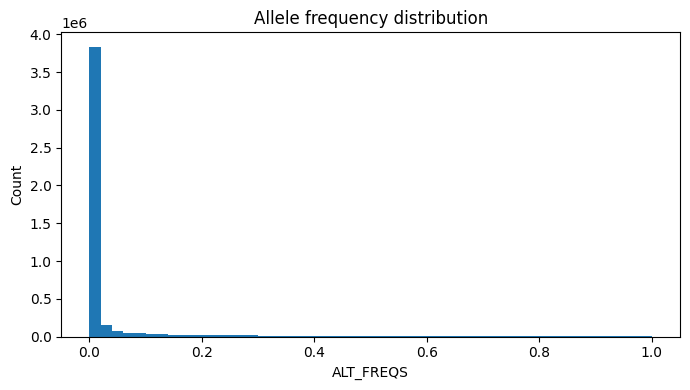

In [22]:
def plot_afreq_distribution(afreq_df):
    if afreq_df is None:
        print("No AFREQ dataframe.")
        return
    
    maf_col = None
    for c in afreq_df.columns:
        if c.upper() in ["ALT_FREQS", "ALT_FREQ", "A1_FREQ"]:
            maf_col = c
            break
    
    if maf_col is None:
        print("No obvious allele frequency column found.")
        print("Columns:", afreq_df.columns.tolist())
        return
    
    s = pd.to_numeric(afreq_df[maf_col], errors="coerce")
    
    plt.figure(figsize=(7, 4))
    plt.hist(s.dropna(), bins=50)
    plt.xlabel(maf_col)
    plt.ylabel("Count")
    plt.title("Allele frequency distribution")
    plt.tight_layout()
    plt.show()

plot_afreq_distribution(afreq_df)

In [23]:
def run_genotype_smoke_test(pheno_path, plink_dir):
    pheno_df = load_pheno_file(pheno_path)
    pheno_info = identify_pheno_columns(pheno_df)
    
    plink_scan_df = scan_plink_directory(plink_dir)
    summarize_plink_scan(plink_scan_df)
    
    prefix = choose_chr1_prefix(plink_scan_df)
    row = get_prefix_row(plink_scan_df, prefix)
    
    psam_df = read_psam(row["psam_path"])
    psam_sample_col = detect_psam_sample_col(psam_df)
    
    sample_cmp = compare_samples(
        pheno_df, pheno_info["sample_col"],
        psam_df, psam_sample_col
    )
    display_sample_comparison(sample_cmp)
    
    merged_df = merge_pheno_psam(
        pheno_df, pheno_info["sample_col"],
        psam_df, psam_sample_col
    )
    
    pvar_df = read_pvar_with_header(row["pvar_path"], row["pvar_zst_path"], nrows=20)
    inspect_pvar_basic(pvar_df)
    
    try:
        n_variants = count_pvar_variants(row["pvar_path"], row["pvar_zst_path"])
    except Exception as e:
        print("Variant counting failed:", e)
        n_variants = None
    
    print("Selected prefix:", prefix)
    print("Estimated variant count:", n_variants)
    
    return {
        "pheno_df": pheno_df,
        "pheno_info": pheno_info,
        "plink_scan_df": plink_scan_df,
        "selected_prefix": prefix,
        "selected_row": row,
        "psam_df": psam_df,
        "sample_cmp": sample_cmp,
        "merged_df": merged_df,
        "pvar_df_preview": pvar_df,
        "n_variants": n_variants,
    }

In [24]:
geno_results = run_genotype_smoke_test(PHENO_PATH, PLINK_DIR)

Phenotype shape: (5811, 16)


,sampleid,sex,age_sd,PC1_sd,PC2_sd,PC3_sd,PC4_sd,PC5_sd,PC6_sd,PC7_sd,PC8_sd,PC9_sd,PC10_sd,cad,bc,T2D
0,S-781185,Male,1.288303,-0.555962,0.480146,0.224748,0.241001,0.320088,1.938814,0.348092,0.387093,0.610129,-0.450001,1,0,0
1,S-312853,Female,1.591000,-0.482392,0.222560,-0.349030,-0.697747,-0.539562,0.463947,-0.214933,0.386187,-0.588972,-0.390756,0,0,0
2,S-879678,Male,0.077515,0.154176,-3.259585,1.898367,-0.280359,-0.868405,0.188799,2.969257,-4.082796,1.091930,1.139250,1,0,1
3,S-964332,Female,-0.770037,1.364458,0.080234,0.323463,-0.224608,1.842692,-0.409662,-1.222077,0.806165,-0.700859,0.216519,0,0,0
4,S-734060,Male,0.440751,-0.562651,0.332478,-0.273394,-1.414405,-0.311043,-0.842868,-0.864892,-0.473900,-1.954522,1.386096,1,0,0


{'sample_col': 'sampleid', 'sex_col': 'sex', 'age_col': 'age_sd', 'pc_cols': ['PC1_sd', 'PC2_sd', 'PC3_sd', 'PC4_sd', 'PC5_sd', 'PC6_sd', 'PC7_sd', 'PC8_sd', 'PC9_sd', 'PC10_sd'], 'phenotype_cols': ['cad', 'bc', 'T2D']}
Number of detected prefixes: 22
Complete triplets: 22
Incomplete entries: 0

Chromosome distribution:


chromosome
1     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
2     1
20    1
21    1
22    1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
Name: count, dtype: int64

,prefix,chromosome,complete_triplet,pgen_size,pvar_size,psam_size
0,Testing_Chr1,1,True,8.53 GB,162.43 MB,101.55 KB
1,Testing_Chr2,2,True,8.93 GB,176.51 MB,101.55 KB
2,Testing_Chr3,3,True,7.62 GB,144.45 MB,101.55 KB
3,Testing_Chr4,4,True,7.63 GB,141.68 MB,101.55 KB
4,Testing_Chr5,5,True,6.79 GB,131.88 MB,101.55 KB
5,Testing_Chr6,6,True,6.49 GB,125.95 MB,101.55 KB
6,Testing_Chr7,7,True,6.28 GB,118.02 MB,101.55 KB
7,Testing_Chr8,8,True,5.79 GB,112.41 MB,101.55 KB
8,Testing_Chr9,9,True,5.29 GB,88.17 MB,101.55 KB
9,Testing_Chr10,10,True,5.34 GB,105.10 MB,101.55 KB


...

Shape: (20, 5)
Columns: ['#CHROM', 'POS', 'ID', 'REF', 'ALT']

Detected columns:
{'chrom_col': '#CHROM', 'pos_col': 'POS', 'id_col': 'ID', 'ref_col': 'REF', 'alt_col': 'ALT'}

Chromosome value counts:


#CHROM
1    20
Name: count, dtype: int64


Duplicated variant IDs: 0

Top REF/ALT combinations:


,REF,ALT,count
0,C,T,7
1,G,A,6
2,A,G,3
3,T,C,1
4,G,C,1
5,C,G,1
6,A,C,1


Selected prefix: Testing_Chr1
Estimated variant count: 4692475
